# 02 Embeddings and shortlist

**Question.** Which embedding backend, topic vector and shortlist size `k` put the right topic in
front of the judge most often?

**Method.** recall@k = share of prompts whose gold topic is among the `k` topics most similar to
the prompt. The gold forest is replayed: prompt *t* is scored against the gold placement of
prompts 1..t-1. Prompts whose gold topic does not exist yet at step *t* are excluded, because
no shortlist can contain them. Gold labels are **drafts** (see 01).

Backends: two local sentence-transformers models (`all-MiniLM-L6-v2`, `bge-small-en-v1.5`) and
TF-IDF as a lexical floor. The plan also asks for an API embedding model. None is configured,
because no provider key is available, so that comparison is open. Topic vector: `centroid`
(mean of the topic's prompts), `label` (the topic name) or `mix` (the mean of the two cosines).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import config, viz
from forest.embed import Embedder, fit_calibration
from forest.evaluate import shortlist_recall
from forest.io import SESSION_IDS, gold_forest, load_gold, load_sessions

viz.style()
cfg = config.load()
sessions = load_sessions()
golds = {sid: load_gold(sid) for sid in SESSION_IDS}
BACKENDS = ["minilm", "bge-small", "tfidf"]
OPTIONS = ["centroid", "label", "mix"]
KS = [1, 3, 5, 8]
FIG = Path(cfg["paths"]["figures"])
MET = Path(cfg["paths"]["metrics"])

## Cosine calibration per backend
Raw cosines live on different scales per model, so they are mapped to [0, 1] before they are mixed
with the judge (`s = gamma * judge + (1 - gamma) * calibrated cosine`). Rule: `lo` = median cosine of
a prompt to the gold topics of the *other* sessions (unrelated), `hi` = 75th percentile of a prompt's
cosine to its own gold topic label. The config holds these values.

In [2]:
emb = {b: Embedder(cfg, b) for b in BACKENDS}
cal = pd.DataFrame({b: fit_calibration(emb[b], sessions, golds) for b in ["minilm", "bge-small"]}).T
cal["config lo"] = [cfg["scores"]["calibration"][b]["lo"] for b in cal.index]
cal["config hi"] = [cfg["scores"]["calibration"][b]["hi"] for b in cal.index]
cal

,lo,hi,config lo,config hi
minilm,0.046,0.555,0.046,0.555
bge-small,0.560,0.776,0.560,0.776


## recall@k

In [3]:
frames = []
for b in BACKENDS:
    for opt in OPTIONS:
        for sid, s in sessions.items():
            d = shortlist_recall(emb[b], s, golds[sid], KS, opt)
            d["backend"], d["option"] = b, opt
            frames.append(d)
recall = pd.concat(frames, ignore_index=True)
table = recall.groupby(["backend", "option", "k"])["hit"].mean().unstack("k").round(3)
recall.to_csv(MET / "shortlist_recall_rows.csv", index=False)
table.to_csv(MET / "shortlist_recall.csv")
print("prompts scored per (backend, option, k):", len(recall) // (len(BACKENDS) * len(OPTIONS) * len(KS)))
table

prompts scored per (backend, option, k): 57


k                       1      3      5      8
backend   option                              
bge-small centroid  0.544  0.807  0.912  0.947
          label     0.614  0.842  0.965  0.982
          mix       0.702  0.895  0.982  0.982
minilm    centroid  0.702  0.912  0.965  0.982
          label     0.737  0.947  0.965  1.000
          mix       0.825  0.982  1.000  1.000
tfidf     centroid  0.509  0.772  0.825  0.930
          label     0.368  0.596  0.754  0.860
          mix       0.632  0.807  0.860  0.947

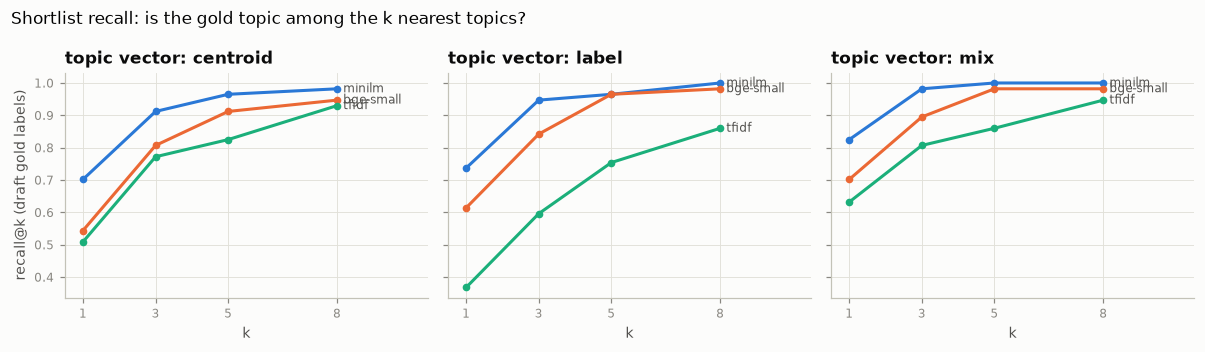

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
colors = {"minilm": viz.SLOTS[0], "bge-small": viz.SLOTS[1], "tfidf": viz.SLOTS[2]}
for ax, opt in zip(axes, OPTIONS):
    for b in BACKENDS:
        y = table.loc[(b, opt)]
        ax.plot(KS, y.values, color=colors[b], marker="o", ms=4)
        ax.annotate(b, (KS[-1], y.values[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8,
                    color=viz.TEXT_2, va="center")
    ax.set_title(f"topic vector: {opt}")
    ax.set_xlabel("k")
    ax.set_xticks(KS)
    ax.set_xlim(0.5, 10.5)
axes[0].set_ylabel("recall@k (draft gold labels)")
fig.suptitle("Shortlist recall: is the gold topic among the k nearest topics?", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
viz.save(fig, FIG / "02_shortlist_recall.png")

## Choice
Best backend and topic vector by recall@3, then recall@1. `k` = the smallest k with recall at
least 0.98 for that setting.

In [5]:
best = table.sort_values([3, 1], ascending=False).index[0]
k_choice = next(k for k in KS if table.loc[best, k] >= 0.98)
print(f"best: backend={best[0]}, topic vector={best[1]}; recall@1={table.loc[best, 1]}, "
      f"recall@3={table.loc[best, 3]}, recall@5={table.loc[best, 5]}; smallest k with recall >= 0.98: {k_choice}")
print(f"config: backend={cfg['embed']['backend']}, topic vector={cfg['embed']['topic_vector']}, k={cfg['shortlist']['k']}")
assert (cfg["embed"]["backend"], cfg["embed"]["topic_vector"]) == best, "update config/default.yaml"

best: backend=minilm, topic vector=mix; recall@1=0.825, recall@3=0.982, recall@5=1.0; smallest k with recall >= 0.98: 3
config: backend=minilm, topic vector=mix, k=5


**Reason recorded in the config:** `minilm` + `mix` has the best recall at every k (table above).
`k = 5` is kept from the plan, one above the smallest k that reaches 0.98, as a margin for topics
the drafts do not cover.

## Shortlist on or off?
At our scale the whole forest fits in the judge prompt. How many topics would the judge see
without a shortlist, and how many with `k = 5` plus parents?

In [6]:
from forest.embed import shortlist

rows = []
for sid, s in sessions.items():
    for p in s.prompts:
        f = gold_forest(s, golds[sid], p.step)
        if not f.topics:
            continue
        sl = shortlist(emb["minilm"], f, p.text, 5, "mix", include_parents=True)
        rows.append({"session": sid, "step": p.step, "topics": len(f.topics), "shortlist": len(sl)})
sizes = pd.DataFrame(rows)
sizes.groupby("session")[["topics", "shortlist"]].agg(["mean", "max"]).round(1)

topics     shortlist    
             mean max      mean max
session                            
s1_focused    6.8  10       4.7   6
s2_mixed      8.8  12       4.7   6
s3_drift      5.9   9       4.7   7

## Findings

- `minilm` with the `mix` topic vector has the best recall on the draft labels at every `k`:
  0.825 at k = 1, 0.982 at k = 3, 1.0 from k = 5 (57 scorable prompts). `bge-small` comes second
  and TF-IDF last. For every backend, `mix` beats `label` and `centroid` alone at k = 1 and k = 3.
- `k = 5` is kept (the smallest k reaching 0.98 is 3). With parents added, the judge sees 4.7
  topics on average (at most 7). Without a shortlist it would see 6 to 9 on average (at most 12),
  so the shortlist saves little at this scale. `shortlist.enabled` stays on so that the setup
  scales to longer sessions.
- The calibration rule reproduces the config values for both models. MiniLM spreads cosines
  more widely (lo 0.05, hi 0.56) than bge (lo 0.56, hi 0.78).
- Open: an API embedding model (no key available), and real gold labels.